In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
from HSA_Cam_A_004 import (
    Chem,
    bmodel,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    plot_model_trace,
    theta_true,
    y0_true,
    sigma,
)
import xarray

In [3]:
plt.style.use("ICIWstyle")

<xarray.DataArray 'temperature' (temperature: 6)> Size: 48B
array([250, 280, 300, 320, 350, 400])
Coordinates:
  * temperature  (temperature) int64 48B 250 280 300 320 350 400

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


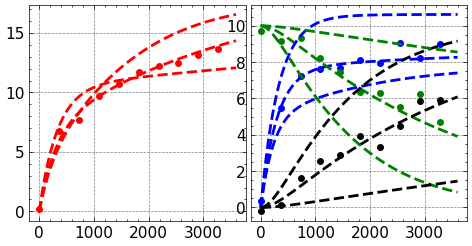

In [4]:
times = np.linspace(0, 1 * 60 * 60, 100)

y_true = xarray.DataArray(
    np.zeros((6, len(times), 4)),
    dims=["temperature", "time", "state"],
    coords={
        "temperature": [250, 280, 300, 320, 350, 400],
        "time": times,
        "state": ["n_g_con", "c_Al", "c_Bl", "c_Cl"],
    },
)
display(y_true.coords["temperature"])

for i, T in enumerate(y_true.coords["temperature"]):
    theta = (
        theta_true[0],
        T,
        theta_true[2],
        theta_true[3],
        theta_true[4],
    )
    y_true[i, :, :] = odeint(Chem.reaction, t=times, y0=y0_true, args=(theta,))
y_true[:, :, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)

# Add noise
t_obs = times[::10]
y_obs = np.random.normal(y_true[1, :, :], sigma)[::10, :]  # downsample and add noise

## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_true_data(axs, times, y_true[1, :, :])
plot_true_data(axs, times, y_true[2, :, :])
plot_true_data(axs, times, y_true[0, :, :])
plot_observed_data(axs, t_obs, y_obs)
plt.show()

In [5]:
model = bmodel(t_obs, y_obs)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Sampling: [A0, EA, LH2, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)


Plotting sample 1/25
theta: (1000000.0, 300, np.float64(0.0012830910124078695), np.float64(3.960985177055733e-05), np.float64(63015.01632714011))
Plotting sample 2/25
theta: (1000000.0, 300, np.float64(0.0014548349309177438), np.float64(0.0030393347014222947), np.float64(58495.64889434961))
Plotting sample 3/25
theta: (1000000.0, 300, np.float64(0.00246424311434195), np.float64(0.00035090879479740886), np.float64(63977.15800196587))
Plotting sample 4/25
theta: (1000000.0, 300, np.float64(0.0039120251333005064), np.float64(1.1171791316692252e-05), np.float64(63029.1413899403))
Plotting sample 5/25
theta: (1000000.0, 300, np.float64(0.0005949017937700167), np.float64(3.995728372632647e-05), np.float64(58344.28197506727))
Plotting sample 6/25
theta: (1000000.0, 300, np.float64(0.002825495980608333), np.float64(0.0001608633734685374), np.float64(53200.48959849222))
Plotting sample 7/25
theta: (1000000.0, 300, np.float64(0.002609969059627414), np.float64(0.00024991099654030915), np.float64(

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


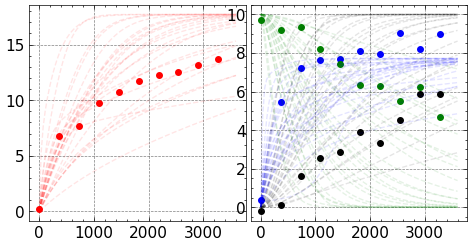

In [6]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_observed_data(axs, t_obs, y_obs)
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

In [7]:
try:
    posterior_idata = az.from_netcdf("HSA_Cam_A_004_posterior.nc")
    print("Loaded posterior from file.")
except FileNotFoundError:
    with model:
        posterior_idata = pm.sample(
            draws=1000,
            tune=500,
            target_accept=0.9,
            random_seed=23489,
            return_inferencedata=True,
            nuts_sampler="numpyro",
        )
    posterior_idata.to_netcdf("HSA_Cam_A_004_posterior.nc")

Loaded posterior from file.


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


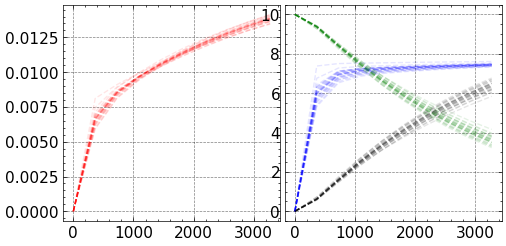

In [8]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)
# display(post_data)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs,
        post_data.values[:, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

<xarray.DataArray 'y_hat' (y_hat_dim_0: 10, y_hat_dim_1: 4, sample: 4000)> Size: 1MB
array([[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [1.00000000e+01, 1.00000000e+01, 1.00000000e+01, ...,
         1.00000000e+01, 1.00000000e+01, 1.00000000e+01],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00]],

       [[5.98345884e-03, 6.12604597e-03, 6.51408983e-03, ...,
         6.72101474e-03, 6.03173591e-03, 6.34946472e-03],
        [5.42086016e+00, 5.58951259e+00, 5.88293848e+00, ...,
         6.11283513e+00, 5.45321958e+00, 5.71080378e+00],
        [9.43740132e+00, 9.46346663e+00, 9.36884865e+00, ...,
         9.39182039e+00, 9.42148368e+00, 9.36133905e+00],
        [5.62598677e-01, 5.36533372e-01, 6.31151354e-01, ...,
         6.08179612e-01, 5.78516324e-01, 6.38660947e-01]],

       [[8.12809489e-03, 8.17462607e-03, 8.50326363e-03, ...,
         8.56158527e-03, 8.17730420e-03, 8.43245072e-03],
...
         5.22312078e+00, 5.43948425e+00, 5.63362034e+00]],

       [[1.32136265e-02, 1.29761877e-02, 1.34119345e-02, ...,
         1.31684630e-02, 1.32977515e-02, 1.35345113e-02],
        [7.30766060e+00, 7.34047811e+00, 7.38492707e+00, ...,
         7.42066981e+00, 7.31293016e+00, 7.35706230e+00],
        [4.09403408e+00, 4.36429038e+00, 3.97299262e+00, ...,
         4.25220678e+00, 4.01517866e+00, 3.82255103e+00],
        [5.90596592e+00, 5.63570962e+00, 6.02700738e+00, ...,
         5.74779322e+00, 5.98482134e+00, 6.17744897e+00]],

       [[1.37419527e-02, 1.34911243e-02, 1.39249376e-02, ...,
         1.36684787e-02, 1.38263922e-02, 1.40558144e-02],
        [7.35288368e+00, 7.37912244e+00, 7.42249789e+00, ...,
         7.45169761e+00, 7.35847512e+00, 7.39954034e+00],
        [3.61093098e+00, 3.88799812e+00, 3.49756029e+00, ...,
         3.78321891e+00, 3.53208290e+00, 3.34372594e+00],
        [6.38906902e+00, 6.11200188e+00, 6.50243971e+00, ...,
         6.21678109e+00, 6.46791710e+00, 6.65627406e+00]]],
      shape=(10, 4, 4000))
Coordinates:
  * y_hat_dim_0  (y_hat_dim_0) int64 80B 0 1 2 3 4 5 6 7 8 9
  * y_hat_dim_1  (y_hat_dim_1) int64 32B 0 1 2 3
  * sample       (sample) object 32kB MultiIndex
  * chain        (sample) int64 32kB 0 0 0 0 0 0 0 0 0 0 ... 3 3 3 3 3 3 3 3 3 3
  * draw         (sample) int64 32kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


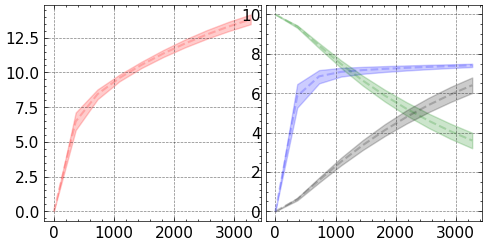

In [9]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
)
display(post_data)

post_data[:, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

# plot_true_data(axs, times, y_true, lw=2)

plot_true_data(
    axs,
    t_obs,
    post_data.values.mean(axis=2),
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 0],
    np.percentile(post_data.values, 95, axis=2)[:, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 1],
    np.percentile(post_data.values, 95, axis=2)[:, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 2],
    np.percentile(post_data.values, 95, axis=2)[:, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 3],
    np.percentile(post_data.values, 95, axis=2)[:, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

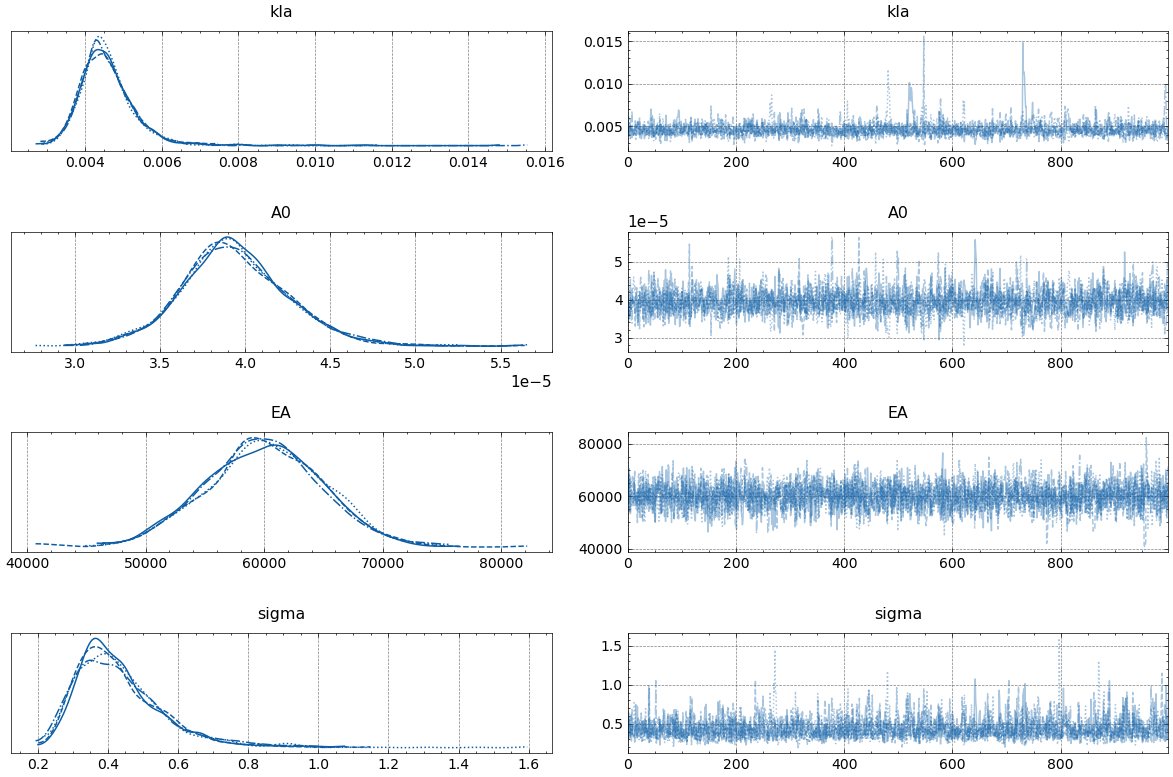

In [10]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "A0",
        "EA",
        "sigma",
    ],
)
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)


Plotting sample 1/25
theta: (1000000.0, 300, np.float64(0.0034807684363726684), np.float64(4.7186500411131476e-05), np.float64(58304.13410625241))
Plotting sample 2/25
theta: (1000000.0, 300, np.float64(0.005950604559327289), np.float64(3.353371078575702e-05), np.float64(52976.72828297827))
Plotting sample 3/25
theta: (1000000.0, 300, np.float64(0.004032065346801615), np.float64(3.935386006337746e-05), np.float64(65971.67248965701))
Plotting sample 4/25
theta: (1000000.0, 300, np.float64(0.005726340302773306), np.float64(3.697343754756804e-05), np.float64(57772.01360595276))
Plotting sample 5/25
theta: (1000000.0, 300, np.float64(0.004777036303366949), np.float64(3.674930494372876e-05), np.float64(62948.36342789274))
Plotting sample 6/25
theta: (1000000.0, 300, np.float64(0.004511150099872898), np.float64(3.6652902086620586e-05), np.float64(64540.77792455207))
Plotting sample 7/25
theta: (1000000.0, 300, np.float64(0.004981006640230734), np.float64(3.752671770673087e-05), np.float64(56

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


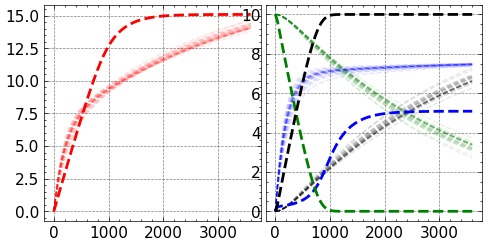

In [15]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

plot_inference(
    axs,
    posterior_idata,
    times=times,
    group="posterior",
    num_samples=25,
    theta_indep=(10e5, 300),
    lw=1,
    alpha=0.1,
)
plot_true_data(axs, times, y_true[5, :, :])